# Who is going to leave? Revolut churn — from a business question to a decision

**Team:** Julien Malherbe & Héloïse Rühl — Track A, ML for Business (MSA-DATB07-08)

**Recommendation (one sentence):** *Ship under condition — send the retention offer only to customers for whom `risk × customer value × offer success rate` exceeds the offer cost, with a **5% cashback on card payments for 30 days, capped at €2**, and measure the real success rate with a control group in the first month.*

**Plan:** 1. Framing · 2. Data audit · 3. Churn definition and time split · 4. Customer value and break-even · 5. Features and leakage check · 6. What goes with churn · 7. Models on validation · 8. Decision rule on validation · **9. Test (opened once)** · 10. Where the model fails · 11. Limits and recommendation

In [1]:
# 0. Check that the data files are next to this notebook
from pathlib import Path

FILES = ['rev-users.csv', 'rev-transactions.csv', 'rev-notifications.csv']
missing = [f for f in FILES if not Path(f).exists()]
assert not missing, f'Missing files: {missing}'
print('OK: all files found')

OK: all files found


In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

users = pd.read_csv('rev-users.csv', parse_dates=['created_date'])
notifs = pd.read_csv('rev-notifications.csv', parse_dates=['created_date'])
tx = pd.read_csv('rev-transactions.csv', parse_dates=['created_date'])
print(users.shape, notifs.shape, tx.shape)
print('Transactions:', tx.created_date.min().date(), '->', tx.created_date.max().date())

(19430, 12) (121813, 5) (2740075, 12)
Transactions: 2018-01-01 -> 2019-05-16


## 1. Framing (before any model)

| Question | Answer |
|---|---|
| Who decides | the retention team |
| Unit | one **active** customer at the cutoff date (at least one transaction in the previous 60 days) |
| When | at the cutoff date, once a month |
| What they do with our output | rank customers and send the offer to the top of the list |
| Constraint | at most `BUDGET` offers per month (assumption) |
| False alarm | we pay the offer `X` for a customer who would have stayed |
| Missed churner | we lose their value `Y` |

**Decision rule.** Sending the offer to one customer earns on average `p × Z × Y − X`:
probability that they leave × probability that the offer keeps them × what they are worth − cost of the offer.
We send it when this is positive: **p × Z × Y > X**.

| Number | Value | Source |
|---|---|---|
| `Y` value of a retained customer (12 months) | computed below, per customer | **data** (fees + card interchange) |
| `X` cost of the offer | **€2** (main scenario), €1 and €5 (sensitivity) | **assumption**, see the offer below |
| `Z` success rate of the offer | 20%, 30%, 50% (scenarios) | **not in the data** (no offer was ever sent) → we show break-even and scenarios |
| `BUDGET` | 500 offers per month (cap) | **assumption**, to confirm with the team |

**Our offer: 5% cashback on card payments for 30 days, capped at €2.**
- It fits the churn profile: customers who leave stop using their card and pay in few categories (section 6); the offer pushes daily card use, the behaviour of customers who stay.
- Its cost is known and capped (€2 per customer), and only paid if the customer uses the card: assuming the full €2 is **conservative**.
- Sensitivity: **€1** (cashback capped at €1) and **€5** (a free month of Premium, at its estimated cost to Revolut).
- The same offer is sent to every targeted customer: what is decided customer by customer is **whether** to send it, not which offer.

In [3]:
BUDGET = 500                     # max offers per month (assumption)
INTERCHANGE = 0.003              # card interchange earned by Revolut (assumption; EU caps 0.2% debit / 0.3% credit)
USD_TO_EUR = 0.89                # average rate early 2019 (assumption)
SCENARIOS_X = [1, 2, 5]          # offer cost in €
SCENARIOS_Z = [0.2, 0.3, 0.5]    # offer success rate

## 2. Data audit

| Finding | Decision |
|---|---|
| 202 transactions above \$100,000, up to \$85 billion (transfers) | data errors: amounts **capped** at the 99th percentile, computed only on data before the first cutoff |
| 58,604 transactions at \$0 | cancelled, pending or declined card payments: kept as a **failure signal**, no effect on amounts |
| Merchant fields empty for 42% of rows | empty only for non-card transactions (complete for card payments): used on card payments only |
| Marketing opt-ins unknown for 34% of users | unknown ≠ no: **filled with 0 together with an "unknown" flag**, so the model can tell "unknown" from "refused" (models do not accept empty cells) |
| `num_referrals`, `num_successful_referrals` always 0 | dropped |
| 664 users with no transaction | never active, so never in our tables |
| 715 notifications dated before signup | one per user, less than 19 h before, onboarding messages: clock shift, kept |
| `plan` | **leak** (plan at export date, may have changed because the customer left): dropped |

In [4]:
print('Transactions > $100,000:', (tx.amount_usd > 1e5).sum())
print('Transactions at $0:', (tx.amount_usd == 0).sum(), tx[tx.amount_usd == 0].transactions_state.value_counts().to_dict())
print('Merchant info missing on card payments:', f"{tx[tx.transactions_type == 'CARD_PAYMENT'].ea_merchant_mcc.isna().mean():.1%}")
print('Opt-in unknown:', f"{users.attributes_notifications_marketing_push.isna().mean():.1%}")
print('Constant columns:', [c for c in users.columns if users[c].nunique() <= 1])
print('Users without transactions:', (~users.user_id.isin(tx.user_id)).sum())
signup = users.set_index('user_id').created_date
print('Notifications before signup:', (notifs.created_date < notifs.user_id.map(signup)).sum())

Transactions > $100,000: 202
Transactions at $0: 58604 {'REVERTED': 31673, 'PENDING': 10747, 'DECLINED': 8180, 'COMPLETED': 8002, 'CANCELLED': 2}


Merchant info missing on card payments: 0.0%
Opt-in unknown: 34.0%
Constant columns: ['num_referrals', 'num_successful_referrals']
Users without transactions: 664
Notifications before signup: 715


## 3. Churn definition and time split

**Rule:** an active customer (at least one transaction in the 60 days before the cutoff) has churned if they make **no transaction in the 60 days after**.

**Why 60 days:** the shorter the window, the more customers we label as churners when they are only taking a break. The cell below shows how many "churners" come back in the following month: 31% with a 45-day window, 26% with 60 days. We keep 60 days; this false-churn rate is an **accepted limit**. 90 days would be cleaner but would push every cutoff back by a month.

In [5]:
cutoff = pd.Timestamp('2019-01-15')
for w in [30, 45, 60, 90]:
    W = pd.Timedelta(days=w)
    active = set(tx[(tx.created_date >= cutoff - W) & (tx.created_date < cutoff)].user_id)
    churners = active - set(tx[(tx.created_date >= cutoff) & (tx.created_date < cutoff + W)].user_id)
    back = tx[(tx.created_date >= cutoff + W) & (tx.created_date < cutoff + W + pd.Timedelta(days=30))]
    print(f'{w} days: churn {len(churners)/len(active):.1%}, '
          f'come back within a month {len(churners & set(back.user_id))/len(churners):.1%}')

30 days: churn 17.2%, come back within a month 39.2%
45 days: churn 17.0%, come back within a month 31.0%


60 days: churn 16.2%, come back within a month 25.8%


90 days: churn 14.9%, come back within a month 15.9%


### 3.1 Cutoff dates

| Part | Cutoff | Label window |
|---|---|---|
| Fit | 14/11/2018 | 14/11/2018 → 12/01/2019 |
| Validation | 14/01/2019 | 14/01/2019 → 14/03/2019 |
| Test (opened once) | 15/03/2019 | 15/03/2019 → 13/05/2019 |

**At least 60 days between two cutoffs.** The label of one part must be fully known before the next cutoff; otherwise the model has already seen part of the answers of the next part (same customers, almost identical features). Transactions end on 16/05/2019, so no label window may go past it.

**Trade-off:** the model learns from November 2018. If behaviour changed since (seasonality, drift), it lags a little: listed in the limits.

In [6]:
WINDOW = pd.Timedelta(days=60)
CUTOFFS = {'fit': pd.Timestamp('2018-11-14'),
           'validation': pd.Timestamp('2019-01-14'),
           'test': pd.Timestamp('2019-03-15')}
last_tx = tx.created_date.max()

for name, c in CUTOFFS.items():
    assert c + WINDOW <= last_tx, f'{name}: label window goes past the end of the data'
    print(f'{name:<11} cutoff {c.date()}  label window {c.date()} -> {(c + WINDOW - pd.Timedelta(days=1)).date()} (60 days)')
dates = list(CUTOFFS.values())
for before, after in zip(dates, dates[1:]):
    assert before + WINDOW <= after, f'overlap between {before.date()} and {after.date()}'
print('No overlap between label windows')

fit         cutoff 2018-11-14  label window 2018-11-14 -> 2019-01-12 (60 days)
validation  cutoff 2019-01-14  label window 2019-01-14 -> 2019-03-14 (60 days)
test        cutoff 2019-03-15  label window 2019-03-15 -> 2019-05-13 (60 days)
No overlap between label windows


### 3.2 What about new customers?

No signup happens after 3 January 2019: the share of recent customers falls to zero in the test set, and they churn almost twice as often. Keeping them would train the model on one population and test it on another.

**Decision: we exclude customers who signed up less than 60 days before the cutoff, in all three parts.** Same population everywhere, 60 days of history for every feature, and a new customer is an onboarding question, not a retention one. **Limit:** the model does not apply to customers younger than two months.

In [7]:
MIN_TENURE = pd.Timedelta(days=60)
rows = []
for name, c in CUTOFFS.items():
    active = tx[(tx.created_date >= c - WINDOW) & (tx.created_date < c)].user_id.unique()
    stayed = set(tx[(tx.created_date >= c) & (tx.created_date < c + WINDOW)].user_id)
    d = pd.DataFrame({'user_id': active})
    d['new'] = (c - d.user_id.map(signup)) < MIN_TENURE
    d['churn'] = ~d.user_id.isin(stayed)
    rows.append({'part': name, 'active': len(d), 'new (<60 days)': int(d.new.sum()),
                 'share new': f'{d.new.mean():.1%}',
                 'churn new': f'{d[d.new].churn.mean():.1%}' if d.new.any() else '-',
                 'churn others': f'{d[~d.new].churn.mean():.1%}'})
pd.DataFrame(rows)

,part,active,new (<60 days),share new,churn new,churn others
0,fit,11217,2976,26.5%,22.8%,16.2%
1,validation,13658,3146,23.0%,23.8%,14.1%
2,test,13068,0,0.0%,-,13.0%


## 4. Customer value and break-even

Observable revenue per active customer over the **90 days before the validation cutoff** (16/10/2018 – 13/01/2019, completed transactions — nothing from the test period): fees + interchange on card payments. It ignores subscriptions and FX margins, so `Y` is **conservative**.

Since `Z` is unknown, we compute the **minimum success rate** that makes the offer profitable, even for a customer who is sure to leave (`p = 1`): `Z > X / Y`.

In [8]:
tx['amount'] = tx.amount_usd.clip(upper=tx.loc[(tx.created_date < CUTOFFS['fit']) & (tx.amount_usd > 0),
                                                 'amount_usd'].quantile(0.99))
# 90 days before the validation cutoff: no information from the test period
period = tx[(tx.created_date >= CUTOFFS['validation'] - pd.Timedelta(days=90)) & (tx.created_date < CUTOFFS['validation'])
            & (tx.transactions_state == 'COMPLETED')]
n_customers, n_months = period.user_id.nunique(), 3
fees = period.loc[period.transactions_type == 'FEE', 'amount'].sum()
card = period.loc[period.transactions_type == 'CARD_PAYMENT', 'amount'].sum()
Y_AVG = (fees + INTERCHANGE * card) / n_customers / n_months * 12 * USD_TO_EUR
print(f'Average value of an active customer: €{Y_AVG:.1f} per year')
for x in SCENARIOS_X:
    print(f'Offer at €{x}: break-even success rate Z = {x / Y_AVG:.0%} (average customer)')

Average value of an active customer: €16.1 per year
Offer at €1: break-even success rate Z = 6% (average customer)
Offer at €2: break-even success rate Z = 12% (average customer)
Offer at €5: break-even success rate Z = 31% (average customer)


## 5. Features — `build_dataset(cutoff)`: one row per active customer

Every feature uses **only** what happened before the cutoff; the label uses only what happens after.

In [9]:
FAILED_STATES = ['DECLINED', 'FAILED', 'REVERTED', 'CANCELLED']
TOP_COUNTRIES = users.country.value_counts().index[:5]

def build_dataset(cutoff):
    past = tx[tx.created_date < cutoff]
    future = tx[(tx.created_date >= cutoff) & (tx.created_date < cutoff + WINDOW)]
    p90 = past[past.created_date >= cutoff - pd.Timedelta(days=90)]
    p30 = past[past.created_date >= cutoff - pd.Timedelta(days=30)]
    ok90 = p90[p90.transactions_state == 'COMPLETED']
    card90 = ok90[ok90.transactions_type == 'CARD_PAYMENT']

    # active customers with at least 60 days of tenure
    active = past[past.created_date >= cutoff - WINDOW].user_id.unique()
    u = users.set_index('user_id').loc[active]
    d = pd.DataFrame(index=u.index)
    d['tenure_days'] = (cutoff - u.created_date).dt.days
    d = d[d.tenure_days >= MIN_TENURE.days]
    idx = d.index
    per_customer = lambda s: s.reindex(idx).fillna(0)

    # Activity
    d['recency_days'] = (cutoff - past.groupby('user_id').created_date.max().reindex(idx)).dt.days
    d['n_tx_30d'] = per_customer(p30.groupby('user_id').size())
    d['n_tx_90d'] = per_customer(p90.groupby('user_id').size())
    d['trend'] = d.n_tx_30d / (d.n_tx_90d / 3 + 1)          # >1 speeding up, <1 slowing down

    # Amounts (completed, capped)
    d['amount_90d'] = per_customer(ok90.groupby('user_id').amount.sum())
    d['avg_basket_90d'] = per_customer(ok90.groupby('user_id').amount.mean())

    # Transaction types (share over 90 days)
    for t in ['CARD_PAYMENT', 'TRANSFER', 'TOPUP', 'EXCHANGE', 'ATM']:
        d[f'share_{t.lower()}'] = per_customer(p90[p90.transactions_type == t].groupby('user_id').size()) / d.n_tx_90d.clip(lower=1)

    # Failures
    d['failure_rate_90d'] = per_customer(p90[p90.transactions_state.isin(FAILED_STATES)].groupby('user_id').size()) / d.n_tx_90d.clip(lower=1)

    # Merchants (card payments only)
    d['n_merchant_countries_90d'] = per_customer(card90.groupby('user_id').ea_merchant_country.nunique())
    d['n_categories_90d'] = per_customer(card90.groupby('user_id').ea_merchant_mcc.nunique())

    # Notifications over 90 days
    n90 = notifs[(notifs.created_date < cutoff) & (notifs.created_date >= cutoff - pd.Timedelta(days=90))]
    d['n_notifs_90d'] = per_customer(n90.groupby('user_id').size())
    d['notif_failure_rate_90d'] = per_customer(n90[n90.status == 'FAILED'].groupby('user_id').size()) / d.n_notifs_90d.clip(lower=1)

    # Profile
    d['age'] = cutoff.year - u.birth_year.reindex(idx)
    d['crypto'] = u.user_settings_crypto_unlocked.reindex(idx)
    d['n_contacts'] = u.num_contacts.reindex(idx)
    for channel in ['push', 'email']:
        col = u[f'attributes_notifications_marketing_{channel}'].reindex(idx)
        d[f'optin_{channel}'] = col.fillna(0)
        d[f'optin_{channel}_unknown'] = col.isna().astype(int)
    country = u.country.reindex(idx).where(u.country.reindex(idx).isin(TOP_COUNTRIES), 'other')
    d = d.join(pd.get_dummies(country, prefix='country', dtype=int))

    # Customer value (€ per year): fees + card interchange over 90 days, annualised
    fees = per_customer(ok90[ok90.transactions_type == 'FEE'].groupby('user_id').amount.sum())
    card = per_customer(card90.groupby('user_id').amount.sum())
    d['value_eur_year'] = (fees + INTERCHANGE * card) * 4 * USD_TO_EUR

    # Label
    d['churn'] = (~d.index.isin(future.user_id)).astype(int)
    return d.reset_index()

fit = build_dataset(CUTOFFS['fit'])
val = build_dataset(CUTOFFS['validation'])
FEATURES = [c for c in fit.columns if c not in ['user_id', 'churn', 'value_eur_year']]
print(f'fit: {len(fit)} customers, churn {fit.churn.mean():.1%}, {len(FEATURES)} features')
print(f'validation: {len(val)} customers, churn {val.churn.mean():.1%}')

fit: 8241 customers, churn 16.2%, 30 features
validation: 10512 customers, churn 14.1%


### 5.1 Leakage check: "on the cutoff date, do I know this value?"

| Column(s) | Known at the cutoff? | Decision |
|---|---|---|
| activity, amounts, types, failures, merchants, notifications | yes: computed only on events before the cutoff | kept |
| tenure, age, country | yes: fixed or almost fixed | kept |
| `crypto`, `n_contacts`, opt-ins | **partly**: snapshot taken at export (May 2019), not at the cutoff | kept, **listed as a limit** |
| `plan` | **no**: plan at export, may have changed because the customer left | **dropped** |
| `num_referrals`, `num_successful_referrals` | always 0 | dropped |
| `value_eur_year` | yes: last 90 days | used for the decision, not as a model feature |

## 6. What goes with churn? (fit set)

For each feature: churn rate among the 25% lowest and the 25% highest values (0 vs 1 for yes/no columns).

⚠️ This shows what goes **with** churn, not what **causes** it.

In [10]:
rows = []
for f in FEATURES:
    x = fit[f]
    if x.nunique() <= 2:
        low, high, ll, lh = fit[x == x.min()].churn.mean(), fit[x == x.max()].churn.mean(), f'= {x.min():g}', f'= {x.max():g}'
    else:
        q1, q3 = x.quantile([0.25, 0.75])
        if q1 == q3:
            low, high, ll, lh = fit[x <= q1].churn.mean(), fit[x > q1].churn.mean(), f'<= {q1:g}', f'> {q1:g}'
        else:
            low, high, ll, lh = fit[x <= q1].churn.mean(), fit[x >= q3].churn.mean(), f'<= {q1:.3g}', f'>= {q3:.3g}'
    rows.append({'feature': f, 'low': ll, 'churn if low': f'{low:.0%}', 'high': lh,
                 'churn if high': f'{high:.0%}', 'gap (points)': round(100 * (high - low))})
print(f'Average churn rate (fit): {fit.churn.mean():.0%}')
pd.DataFrame(rows).sort_values('gap (points)', key=abs, ascending=False).head(15)

Average churn rate (fit): 16%


,feature,low,churn if low,high,churn if high,gap (points)
1,recency_days,<= 1,2%,>= 19,41%,38
2,n_tx_30d,<= 1,39%,>= 25,2%,-37
3,n_tx_90d,<= 11,34%,>= 73,4%,-30
4,trend,<= 0.283,36%,>= 1.28,9%,-28
5,amount_90d,<= 216,31%,>= 2.77e+03,6%,-25
14,n_categories_90d,<= 2,30%,>= 12,6%,-24
13,n_merchant_countries_90d,<= 1,26%,>= 3,6%,-20
19,n_contacts,<= 0,27%,>= 21,8%,-19
28,country_RO,= 0,17%,= 1,7%,-10
26,country_IE,= 0,17%,= 1,8%,-9


**Reading** (average churn 16%):
1. **Disengagement is the strongest signal.** No transaction for 19+ days: 41% churn, vs 2% for customers active the day before. Same for few transactions in 30 days and a slowing trend.
2. **Narrow use is fragile use.** ≤2 merchant categories: 30% churn vs 6% above 12; one merchant country: 26% vs 6%. Customers who use Revolut as their main account stay.
3. **Few social ties, more churn.** 0 contacts: 27% vs 8% above 21.
4. **Country matters a little.** UK 21%, Ireland and Romania 7–8%.
5. **Matters little:** payment failures, age, notifications, opt-ins.

These are associations: a customer who leaves stops using the card, so few categories is a **symptom**, not necessarily a reason.

## 7. Models on validation

**Baseline (one line):** the longer a customer has been inactive, the riskier → rank by `recency_days`.

Metric: **PR-AUC** (average precision), to compare with the churn rate (~14%), and **churners among the 500 top-ranked customers**. Accuracy is useless at this churn rate.

In [11]:
def trees(depth=3, lr=0.03, n=300):
    return HistGradientBoostingClassifier(max_depth=depth, learning_rate=lr, max_iter=n, random_state=0)
def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

scores = {'random': None, 'baseline (recency)': val.recency_days,
          'logistic regression': logit().fit(fit[FEATURES], fit.churn).predict_proba(val[FEATURES])[:, 1],
          'boosted trees': trees().fit(fit[FEATURES], fit.churn).predict_proba(val[FEATURES])[:, 1]}

def compare(data, scores):
    rows = []
    for name, s in scores.items():
        if s is None:
            rows.append({'method': name, 'PR-AUC': round(data.churn.mean(), 3),
                         'churners in top 500': round(data.churn.mean() * BUDGET)})
        else:
            top = data.assign(s=s).nlargest(BUDGET, 's')
            rows.append({'method': name, 'PR-AUC': round(average_precision_score(data.churn, s), 3),
                         'churners in top 500': int(top.churn.sum())})
    return pd.DataFrame(rows)
compare(val, scores)

,method,PR-AUC,churners in top 500
0,random,0.141,71
1,baseline (recency),0.385,229
2,logistic regression,0.450,275
3,boosted trees,0.472,298


### 7.1 Tuning the trees (validation only)

Three settings: **depth** (questions in a row per tree), **learning rate** (share of each correction we accept), **number of trees**. We keep the best PR-AUC on validation.

In [12]:
trials = []
for depth in [3, 4, 6]:
    for lr in [0.03, 0.05, 0.1]:
        for n in [100, 300]:
            p = trees(depth, lr, n).fit(fit[FEATURES], fit.churn).predict_proba(val[FEATURES])[:, 1]
            trials.append({'depth': depth, 'learning rate': lr, 'trees': n,
                           'PR-AUC': round(average_precision_score(val.churn, p), 4)})
pd.DataFrame(trials).sort_values('PR-AUC', ascending=False).head(5)

,depth,learning rate,trees,PR-AUC
1,3,0.03,300,0.4725
4,3,0.10,100,0.4710
2,3,0.05,100,0.4702
0,3,0.03,100,0.4696
6,4,0.03,100,0.4682


Best setting: depth 3, learning rate 0.03, 300 trees (used everywhere above and below). The top settings are very close: tuning helps a little. Shallow trees limit memorising.

### 7.2 Calibration: when the model says 40%, do 40% leave?

The decision rule uses `p` as a real probability, so we check it.

In [13]:
p_val = scores['boosted trees']
t = pd.DataFrame({'p': p_val, 'churn': val.churn})
t['bucket'] = pd.cut(t.p, [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1])
t.groupby('bucket', observed=True).agg(customers=('churn', 'size'), mean_p=('p', 'mean'), actual_churn=('churn', 'mean')).round(3)

,customers,mean_p,actual_churn
bucket,,,
"(0.0, 0.05]",4461,0.017,0.011
"(0.05, 0.1]",1317,0.074,0.054
"(0.1, 0.2]",1718,0.145,0.140
"(0.2, 0.3]",960,0.246,0.271
"(0.3, 0.5]",1340,0.398,0.350
"(0.5, 0.7]",631,0.579,0.534
"(0.7, 1.0]",85,0.741,0.694


**Reading:** predicted and actual rates match within a few points up to 50%; above that the model is slightly optimistic. We can use `p` in the rule.

### 7.3 Trees vs logistic regression: real edge or luck?

Same comparison on 3 periods (train on one cutoff, evaluate on the next, always 60 days apart). The test set is never used.

In [14]:
periods = [('2018-07-16', '2018-09-14'), ('2018-09-14', '2018-11-14'), ('2018-11-14', '2019-01-14')]
cache, rows = {}, []
for c_train, c_eval in periods:
    for c in [c_train, c_eval]:
        cache.setdefault(c, build_dataset(pd.Timestamp(c)))
    tr, ev = cache[c_train], cache[c_eval]
    for name, model in [('logistic', logit()), ('trees', trees())]:
        p = model.fit(tr[FEATURES], tr.churn).predict_proba(ev[FEATURES])[:, 1]
        rows.append({'evaluated on': c_eval, 'model': name,
                     'churners in top 500': int(ev.assign(p=p).nlargest(BUDGET, 'p').churn.sum())})
pd.DataFrame(rows).pivot(index='evaluated on', columns='model', values='churners in top 500')

model,logistic,trees
evaluated on,,
2018-09-14,269,279
2018-11-14,288,318
2019-01-14,275,298


**Reading:** the trees beat the logistic regression on all 3 periods: the edge is not luck. **Chosen model: boosted trees.** Performance moves from one period to the next: the model must be retrained regularly.

## 8. Decision rule on validation

Five ways to choose who gets the offer:

| Strategy | Who receives the offer |
|---|---|
| A. Baseline recency | the 500 customers inactive for longest |
| B. Biggest spenders (no model) | the 500 customers with the highest value |
| C. Risk (trees) | the 500 customers with the highest `p` |
| D. Expected loss (trees) | the 500 customers with the highest `p × value` |
| E. Profitability rule (trees) | only if `p × Z × value > X`, at most 500 |

Real gain = Σ (targeted churners × Z × their value) − offers × X.

In [15]:
def strategies(data, x, z):
    rule = data.assign(g=data.p * z * data.value_eur_year - x)
    return {'A. baseline recency': data.nlargest(BUDGET, 'recency_days'),
            'B. biggest spenders': data.nlargest(BUDGET, 'value_eur_year'),
            'C. risk (trees)': data.nlargest(BUDGET, 'p'),
            'D. expected loss (trees)': data.assign(k=data.p * data.value_eur_year).nlargest(BUDGET, 'k'),
            'E. profitability rule': rule[rule.g > 0].nlargest(BUDGET, 'g')}

def estimate(data):
    rows = []
    for x in SCENARIOS_X:
        for z in SCENARIOS_Z:
            for name, targets in strategies(data, x, z).items():
                rows.append({'X (€)': x, 'Z': f'{z:.0%}', 'strategy': name, 'offers': len(targets),
                             'churners targeted': int(targets.churn.sum()),
                             'gain €': round((targets.churn * z * targets.value_eur_year).sum() - len(targets) * x)})
    return pd.DataFrame(rows)

val_est = estimate(val.assign(p=p_val))
val_est.pivot_table(index='strategy', columns=['X (€)', 'Z'], values='gain €')

X (€)                         1                     2                      5  \
Z                           20%    30%     50%    20%    30%     50%     20%   
strategy                                                                       
A. baseline recency      -349.0 -273.0  -122.0 -849.0 -773.0  -622.0 -2349.0   
B. biggest spenders      -283.0 -174.0    43.0 -783.0 -674.0  -457.0 -2283.0   
C. risk (trees)          -167.0    0.0   334.0 -667.0 -500.0  -166.0 -2167.0   
D. expected loss (trees)  445.0  917.0  1862.0  -55.0  417.0  1362.0 -1555.0   
E. profitability rule     445.0  917.0  1862.0  178.0  452.0  1362.0    52.0   

X (€)                                     
Z                            30%     50%  
strategy                                  
A. baseline recency      -2273.0 -2122.0  
B. biggest spenders      -2174.0 -1957.0  
C. risk (trees)          -2000.0 -1666.0  
D. expected loss (trees) -1083.0  -138.0  
E. profitability rule      101.0   445.0

**Reading (validation):** targeting the riskiest customers (C) loses money: they are dormant customers who earn almost nothing. Adding customer value (D, E) changes everything, and the profitability rule (E) is the only strategy that is positive in every scenario.

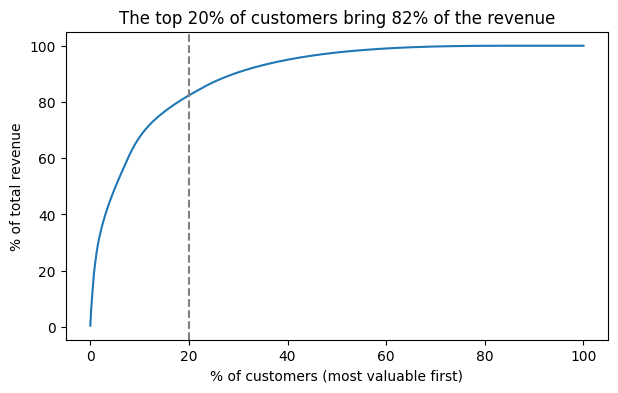

Top 20% of customers: 82% of revenue | bottom 50%: 2% of revenue


In [16]:
import matplotlib.pyplot as plt

values = val.value_eur_year.sort_values(ascending=False)        # customers from most to least valuable
share_customers = np.arange(1, len(values) + 1) / len(values)    # x: share of customers
share_revenue = values.cumsum() / values.sum()                    # y: share of total revenue
top20 = share_revenue.iloc[int(0.2 * len(values)) - 1]

plt.figure(figsize=(7, 4))
plt.plot(share_customers * 100, share_revenue.values * 100)
plt.axvline(20, color='grey', linestyle='--')
plt.xlabel('% of customers (most valuable first)')
plt.ylabel('% of total revenue')
plt.title(f'The top 20% of customers bring {top20:.0%} of the revenue')
plt.show()

top50 = (share_customers <= 0.5).sum()
print(f'Top 20% of customers: {top20:.0%} of revenue | bottom 50%: {1 - share_revenue.iloc[top50 - 1]:.0%} of revenue')

**Reading:** revenue is extremely concentrated — the **top 20% of customers bring 82% of the revenue**, while the bottom half brings only 2%. Losing one high-value customer costs as much as losing dozens of small ones: this is why the decision must rank customers by **risk × value**, not by risk alone.

# 9. TEST — opened here, once

**Frozen before opening:** 60-day churn; active customers with ≥60 days of tenure; the features of `build_dataset`; boosted trees (depth 3, learning rate 0.03, 300 trees); final training on fit + validation (cutoffs 14/11/2018 and 14/01/2019, all labels known before 15/03/2019); profitability rule capped at 500 offers.

Nothing is changed after this point.

In [17]:
test = build_dataset(CUTOFFS['test'])
train = pd.concat([fit, val], ignore_index=True)
final_trees = trees().fit(train[FEATURES], train.churn)
final_logit = logit().fit(train[FEATURES], train.churn)
test['p'] = final_trees.predict_proba(test[FEATURES])[:, 1]
print(f'final training: {len(train)} rows; test: {len(test)} customers, churn {test.churn.mean():.1%}')
compare(test, {'random': None, 'baseline (recency)': test.recency_days,
               'logistic regression': final_logit.predict_proba(test[FEATURES])[:, 1],
               'boosted trees': test.p})

final training: 18753 rows; test: 13068 customers, churn 13.0%


,method,PR-AUC,churners in top 500
0,random,0.130,65
1,baseline (recency),0.372,246
2,logistic regression,0.425,279
3,boosted trees,0.466,297


In [18]:
test_est = estimate(test)
test_est.pivot_table(index='strategy', columns=['X (€)', 'Z'], values='gain €')

X (€)                         1                      2                  \
Z                           20%     30%     50%    20%     30%     50%   
strategy                                                                 
A. baseline recency      -245.0  -118.0   137.0 -745.0  -618.0  -363.0   
B. biggest spenders       409.0   864.0  1773.0  -91.0   364.0  1273.0   
C. risk (trees)          -315.0  -222.0   -36.0 -815.0  -722.0  -536.0   
D. expected loss (trees)  975.0  1712.0  3187.0  475.0  1212.0  2687.0   
E. profitability rule     975.0  1712.0  3187.0  712.0  1338.0  2687.0   

X (€)                          5                  
Z                            20%     30%     50%  
strategy                                          
A. baseline recency      -2245.0 -2118.0 -1863.0  
B. biggest spenders      -1591.0 -1136.0  -227.0  
C. risk (trees)          -2315.0 -2222.0 -2036.0  
D. expected loss (trees) -1025.0  -288.0  1187.0  
E. profitability rule      554.0   925.0  1780.0

In [19]:
# Profitability rule (E) in detail
test_est[test_est.strategy == 'E. profitability rule'].pivot_table(index='X (€)', columns='Z', values=['offers', 'churners targeted', 'gain €'])

churners targeted             gain €                 offers         \
Z                   20%   30%   50%    20%     30%     50%    20%    30%   
X (€)                                                                      
1                  89.0  89.0  89.0  975.0  1712.0  3187.0  500.0  500.0   
2                  55.0  74.0  89.0  712.0  1338.0  2687.0  265.0  390.0   
5                  28.0  38.0  55.0  554.0   925.0  1780.0   70.0  132.0   

              
Z        50%  
X (€)         
1      500.0  
2      500.0  
5      265.0

### 9.1 Who receives the offer? (profitability rule, €2 offer, Z = 30%, test)

In [20]:
targets = strategies(test, 2, 0.30)['E. profitability rule']
tiers = pd.qcut(test.value_eur_year.rank(method='first'), 3, labels=['1. low value', '2. medium value', '3. high value'])
country_cols = [c for c in test.columns if c.startswith('country_')]
country = test[country_cols].idxmax(axis=1).str.replace('country_', '')

who = pd.DataFrame({'value tier': tiers, 'country': country, 'targeted': test.index.isin(targets.index),
                    'churn': test.churn})
summary = who.groupby('value tier', observed=True).agg(customers=('churn', 'size'), churn_rate=('churn', 'mean'),
                                                        offers=('targeted', 'sum'))
summary['share of offers'] = summary.offers / summary.offers.sum()
print(summary.round(2).to_string()); print()
print(who[who.targeted].groupby('country').size().rename('offers').sort_values(ascending=False).to_string())

                 customers  churn_rate  offers  share of offers
value tier                                                     
1. low value          4356        0.25       0              0.0
2. medium value       4356        0.10       0              0.0
3. high value         4356        0.05     390              1.0

country
GB       194
other    108
FR        49
RO        17
PL        12
IE        10


**Reading:** the offers go almost only to **high-value** customers at risk, although churn is highest among low-value customers: a low-value customer is never worth €2. This is the profile-based allocation of the offer.

In [21]:
# Stability: validation vs test, reference scenario (X = €2, Z = 30%, rule E)
ref = lambda e: e[(e['X (€)'] == 2) & (e.Z == '30%') & (e.strategy == 'E. profitability rule')]['gain €'].item()
print(f'validation: €{ref(val_est)} per month   |   test: €{ref(test_est)} per month')

validation: €452 per month   |   test: €1338 per month


**Reading (test):**
- The trees stay the best model on unseen data (297 churners in the top 500, vs 279 logistic, 246 baseline, 65 random): **the model is stable**.
- **Targeting the riskiest (C) loses money in every scenario.** Biggest spenders without a model (B) already do better: value matters more than risk.
- **The profitability rule (E) is the only strategy positive in all 9 scenarios.** At €5 per offer it sends only 70–265 offers and still gains, when every other strategy loses money.
- The test gain is about 3 times the validation gain for the same scenario. Two reasons: the final model is trained on two periods (fit + validation) instead of one, and the test period is different (maybe easier). **We announce a range, not a single number: about €450 to €1,340 per month for a €2 offer and Z = 30%.**

# 10. Where the model fails (test)

## 10.1 By group: share of churners caught in the 500 riskiest customers

In [22]:
t = test.copy()
t['caught'] = t.index.isin(t.nlargest(BUDGET, 'p').index)
country_cols = [c for c in t.columns if c.startswith('country_')]
t['country'] = t[country_cols].idxmax(axis=1).str.replace('country_', '')
t['tenure'] = pd.cut(t.tenure_days, [0, 180, 365, 10_000], labels=['2-6 months', '6-12 months', '> 1 year'])
t['activity (tx 90d)'] = pd.qcut(t.n_tx_90d, 4, labels=['low', 'medium', 'high', 'very high'])
t['value'] = pd.qcut(t.value_eur_year.rank(method='first'), 4, labels=['small', 'medium', 'large', 'very large'])

def by_group(col):
    return t.groupby(col, observed=True).apply(lambda d: pd.Series({
        'customers': len(d), 'churn rate': f'{d.churn.mean():.0%}', 'churners': int(d.churn.sum()),
        'churners caught': f'{d[d.churn == 1].caught.mean():.0%}'}), include_groups=False)

for col in ['activity (tx 90d)', 'value', 'country', 'tenure']:
    print(f'--- {col}'); print(by_group(col).to_string()); print()

--- activity (tx 90d)


                   customers churn rate  churners churners caught
activity (tx 90d)                                                
low                     3301        31%      1023             26%
medium                  3322        13%       446              4%
high                    3205         6%       186              5%
very high               3240         2%        49              4%

--- value
            customers churn rate  churners churners caught
value                                                     
small            3267        28%       908             28%
medium           3267        13%       425              3%
large            3267         7%       223              4%
very large       3267         5%       148             16%

--- country
         customers churn rate  churners churners caught
country                                                
FR            1387        15%       206             17%
GB            3842        16%       603             19%
IE

**Reading:**
- The model catches customers who **fade out**: low activity (26% caught), low value (28%).
- It misses almost every **churner who was still active**: only 4–5% caught at medium to very high activity.
- Weaker in Ireland (7%) and Romania (11%), where churn is rare. No clear weakness by tenure.

## 10.2 The most expensive mistakes

**Missed churners:** high-value customers who left while the model rated them low-risk.

In [23]:
cols = ['p', 'value_eur_year', 'recency_days', 'n_tx_30d', 'n_tx_90d', 'trend', 'n_categories_90d', 'n_contacts', 'tenure_days']
t[t.churn == 1].assign(loss=lambda d: d.value_eur_year * (1 - d.p)).nlargest(10, 'loss')[cols].round(2)

,p,value_eur_year,recency_days,n_tx_30d,n_tx_90d,trend,n_categories_90d,n_contacts,tenure_days
5196,0.02,409.21,0,10.0,18,1.43,3.0,9,232
1289,0.20,431.32,22,3.0,68,0.13,17.0,0,338
2482,0.22,427.48,6,18.0,18,2.57,3.0,7,320
7826,0.27,409.28,48,0.0,21,0.00,1.0,76,92
67,0.09,250.19,9,5.0,15,0.83,1.0,0,395
5533,0.13,258.80,14,45.0,46,2.76,13.0,7,391
11985,0.18,273.53,24,1.0,58,0.05,16.0,29,87
5027,0.14,254.33,26,3.0,19,0.41,6.0,24,428
6359,0.15,256.32,4,1.0,2,0.60,0.0,0,411
10534,0.32,256.32,27,3.0,7,0.90,0.0,0,148


**Reading:** the most expensive misses (€250–430 per year) were **still active** (last transaction 0–26 days before), often with rising activity. Nothing in their transactions announced the departure (moving, switching banks, reasons outside our data).

**False alarms:** customers rated riskiest who stayed.

In [24]:
t[t.churn == 0].nlargest(10, 'p')[cols].round(2)

,p,value_eur_year,recency_days,n_tx_30d,n_tx_90d,trend,n_categories_90d,n_contacts,tenure_days
13033,0.78,0.0,34,0.0,1,0.00,0.0,0,90
13032,0.74,0.0,37,0.0,1,0.00,0.0,0,213
1265,0.72,0.0,56,0.0,2,0.00,0.0,0,322
3362,0.69,0.0,51,0.0,1,0.00,0.0,0,294
10187,0.69,0.0,53,0.0,1,0.00,0.0,0,148
7689,0.69,0.0,50,0.0,6,0.00,0.0,3,76
10662,0.69,0.0,58,0.0,20,0.00,0.0,0,75
6426,0.68,0.0,48,0.0,1,0.00,0.0,0,397
6224,0.68,0.0,20,1.0,1,0.75,0.0,0,395
10141,0.68,0.0,54,0.0,1,0.00,0.0,0,211


**Reading:** false alarms are dormant customers (1 transaction in 90 days, value €0). **They cost nothing under the profitability rule**: their value is zero, so they never receive an offer.

# 11. Limits and recommendation

**Limits of the model**
- It does not see **sudden departures of active customers**, the most expensive ones.
- It does not apply to customers younger than **two months**.
- It learns from **November 2018 – January 2019**: behaviour drifts, it must be retrained monthly.

**Caveats of the dataset**
- **No offer was ever sent**: the success rate `Z` is unknown, and the model predicts who leaves, not who an offer would keep.
- **Customer value is a lower bound** (fees + interchange only) and assumes a retained customer keeps their last-90-day pace for a year.
- `crypto`, `n_contacts` and opt-ins are a **snapshot at export**, not at the cutoff.
- **26% of labelled churners come back within a month** (60-day window): some "churners" were only taking a break.
- Offer cost, interchange rate and budget are **assumptions**.

**Recommendation: ship under condition.**
Rank customers by risk × value and send the offer only when `p × Z × value > X`, with a **5% cashback on card payments for 30 days, capped at €2**. Expected gain: about **€450 to €1,340 per month** (X = €2, Z = 30%).

**What we check in the first month**
1. **A/B test with a control group** among targeted customers, to measure the real success rate `Z`. If `Z` is below the break-even, stop.
2. Actual churn of targeted customers vs the predicted `p` (calibration).
3. Monthly retraining and the gain per month: stop if it turns negative.

**Next step:** once the A/B test gives real responses, test different offers by profile (e.g. a Premium month for high-value customers with payment failures) and learn which offer works for whom (uplift modelling).